Loading the data efficiently

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Efficient loading with correct dtypes (avoids OOM on 6M rows)
dtypes = {
    'step': 'int16',
    'type': 'category',
    'amount': 'float32',
    'nameOrig': 'str',
    'oldbalanceOrg': 'float32',
    'newbalanceOrig': 'float32',
    'nameDest': 'str',
    'oldbalanceDest': 'float32',
    'newbalanceDest': 'float32',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8',
}

df = pd.read_csv('../data/raw/PS_20174392719_1491204439457_log.csv', dtype=dtypes)
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()


Shape: (6362620, 11)
Columns: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.639648,C1231006815,170136.0,160296.359375,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.280029,C1666544295,21249.0,19384.720703,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.000000,C1305486145,181.0,0.000000,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.000000,C840083671,181.0,0.000000,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.139648,C2048537720,41554.0,29885.859375,M1230701703,0.0,0.0,0,0


class imbalance

In [2]:
total = len(df)
fraud = df['isFraud'].sum()
print(f"Total transactions: {total:,}")
print(f"Fraud: {fraud:,} ({fraud/total*100:.3f}%)")
print(f"Non-fraud: {total-fraud:,}")

# Fraud by type
print("\nFraud by type:")
print(df.groupby('type')['isFraud'].agg(['count', 'sum', 'mean'])
      .rename(columns={'mean': 'fraud_rate'})
      .sort_values('sum', ascending=False))


Total transactions: 6,362,620
Fraud: 8,213 (0.129%)
Non-fraud: 6,354,407

Fraud by type:
            count   sum  fraud_rate
type                               
CASH_OUT  2237500  4116    0.001840
TRANSFER   532909  4097    0.007688
CASH_IN   1399284     0    0.000000
DEBIT       41432     0    0.000000
PAYMENT   2151495     0    0.000000


/tmp/ipykernel_110321/3586874730.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('type')['isFraud'].agg(['count', 'sum', 'mean'])


Check time split fraud counts (CRITICAL):

In [4]:
# These must each have >= 500 fraud cases
train = df[df['step'] <= 500]
val = df[(df['step'] >= 501) & (df['step'] <= 620)]
test = df[df['step'] >= 621]

for name, split in [('Train', train), ('Val', val), ('Test', test)]:
    fraud_count = split['isFraud'].sum()
    status = "✅" if fraud_count >= 500 else "❌ TOO FEW"
    print(f"{name}: {len(split):,} rows, {fraud_count} fraud cases {status}")


Train: 6,061,807 rows, 5561 fraud cases ✅
Val: 209,984 rows, 1286 fraud cases ✅
Test: 90,829 rows, 1366 fraud cases ✅


Amount distribution

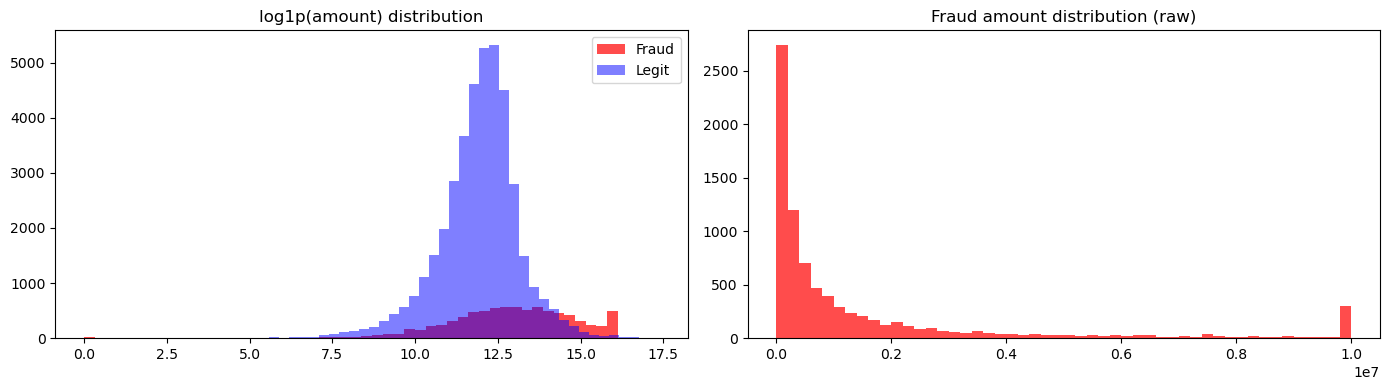


Fraud amount stats:
count    8.213000e+03
mean     1.467967e+06
std      2.404254e+06
min      0.000000e+00
25%      1.270913e+05
50%      4.414234e+05
75%      1.517772e+06
max      1.000000e+07
Name: amount, dtype: float64

99th percentile of scored fraud-eligible transactions: 2650035.56


In [5]:
# Focus on the scored types only
scored = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])]
fraud_amounts = scored[scored['isFraud'] == 1]['amount']
legit_amounts = scored[scored['isFraud'] == 0]['amount']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(np.log1p(fraud_amounts), bins=50, alpha=0.7, label='Fraud', color='red')
axes[0].hist(np.log1p(legit_amounts.sample(min(len(fraud_amounts)*5, len(legit_amounts)))), 
             bins=50, alpha=0.5, label='Legit', color='blue')
axes[0].set_title('log1p(amount) distribution')
axes[0].legend()

axes[1].hist(fraud_amounts, bins=50, alpha=0.7, color='red')
axes[1].set_title('Fraud amount distribution (raw)')
plt.tight_layout()
plt.savefig('../reports/figures/amount_dist.png', dpi=100)
plt.show()

print(f"\nFraud amount stats:\n{fraud_amounts.describe()}")
print(f"\n99th percentile of scored fraud-eligible transactions: {scored['amount'].quantile(0.99):.2f}")


Fraud over time (check for spikes)

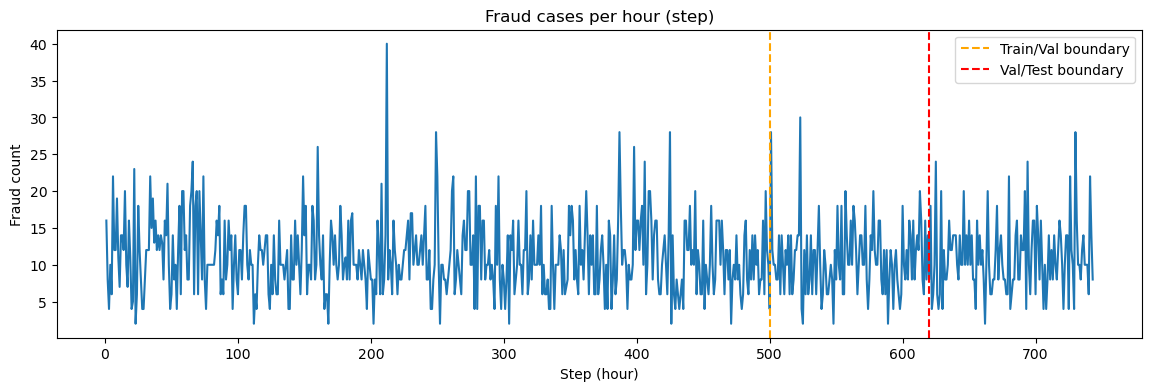

In [6]:
fraud_by_step = df[df['isFraud'] == 1].groupby('step').size()
plt.figure(figsize=(14, 4))
fraud_by_step.plot()
plt.axvline(x=500, color='orange', linestyle='--', label='Train/Val boundary')
plt.axvline(x=620, color='red', linestyle='--', label='Val/Test boundary')
plt.title('Fraud cases per hour (step)')
plt.xlabel('Step (hour)')
plt.ylabel('Fraud count')
plt.legend()
plt.savefig('../reports/figures/fraud_over_time.png', dpi=100)
plt.show()